# Idorsia rNPV, working notebook

*A risk adjusted NPV of Idorsia's pipeline, product by product.*

This notebook is the reproducible workbook behind the site's
[Results](../results.html) page. Every input is either sourced to a
public document or explicitly flagged as an assumption in
[`src/assumptions.py`](https://github.com/DimitriPr/rnpv-idorsia-valuation/blob/main/src/assumptions.py). The narrative
version of the conclusions lives in `results.qmd`; this notebook is the
audit trail.

**Structure**

1. Idorsia at a glance, market data and 2025 financials
2. The structural puzzle, parent Ltd vs Idorsia Investments SARL
3. Assumptions, pipeline, PoS benchmarks, discount rate
4. Revenue projections
5. Product level rNPVs
6. Enterprise value bridge
7. Sensitivities
8. Scenarios, fair value vs market
9. Verdict and limitations

In [1]:
%matplotlib inline
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, display

from src import assumptions as A
from src import rnpv
from src import sensitivity as S

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
FIG_DIR = ROOT / "outputs" / "figures"

## 1. Idorsia at a glance

Idorsia Ltd (SIX: IDIA) is a Swiss specialty biotech founded on the
scientific legacy of Actelion. It runs one commercial product
(**QUVIVIQ / daridorexant**, insomnia, approved US 2022, EU 2022) and
a clinical pipeline led by lucerastat (Phase 3, Fabry disease). A second
approved product, **TRYVIO / JERAYGO** (aprocitentan, resistant
hypertension), was **transferred in 2025 to a ring fenced subsidiary**
(Idorsia Investments SARL) to service CHF 762 M of restructured notes
we come back to this in §2.

Market and share data as of 31 Dec 2025:

In [2]:
snapshot = pd.DataFrame({
    "Metric": [
        "Share price, close 31/12/25",
        "Shares outstanding (Q1 2026, 31/03/26)",
        "Market cap 31/12/25",
        f"Share price, latest ({A.SHARE_PRICE_STATUS})",
        "Fully diluted potential shares",
        "Valuation date",
    ],
    "Value": [
        f"CHF {A.SHARE_PRICE_YE2025_CHF:.2f}",
        f"{A.SHARES_OUTSTANDING_M:.1f} M",
        f"CHF {A.MARKET_CAP_YE2025_CHF_M:,.0f} M",
        f"CHF {A.SHARE_PRICE_CURRENT_CHF:.2f}  (as of {A.SHARE_PRICE_CURRENT_AS_OF})",
        f"{A.POTENTIAL_SHARES_FULLY_DILUTED_M:.1f} M",
        A.VALUATION_DATE,
    ],
})
snapshot

,Metric,Value
0,"Share price, close 31/12/25",CHF 4.26
1,"Shares outstanding (Q1 2026, 31/03/26)",254.0 M
2,Market cap 31/12/25,"CHF 1,070 M"
3,"Share price, latest (sourced)",CHF 4.22 (as of 2026-10-13)
4,Fully diluted potential shares,317.1 M
5,Valuation date,2026-06-30


Full year 2025 non GAAP (from the AR): net revenue CHF 214 M, operating
loss CHF 100 M, net loss CHF 118 M. QUVIVIQ sales more than doubled YoY
(2024 → 2025: CHF 61 M → 134 M). 2026 guidance is QUVIVIQ CHF 200 M,
non GAAP EBIT CHF –120 M, implying a materially narrower operating loss.

## 2. The structural puzzle, parent vs SARL

This is the single point on which naïve valuations of Idorsia go wrong.

In May 2025 Idorsia transferred the rights to **aprocitentan (TRYVIO /
JERAYGO)**, **selatogrel** and **cenerimod** to a newly created
subsidiary, **Idorsia Investments SARL**. That SARL secures CHF 762 M of
notes maturing 2048/2050. Rights only revert to the parent (Idorsia Ltd,
SIX listed) *after* the SARL debt + interest are fully repaid. The CHF
150 M SARL New Money Facility (CHF 105 M drawn) was repaid in full on
26 Jun 2026 using proceeds from the new Pharmakon term loan at op co.

For an equity holder of IDIA, this means:

- **What the parent captures directly**: QUVIVIQ + the R&D pipeline
  (lucerastat, CCR6, CXCR7, CXCR3, C. diff vaccine).
- **What the parent captures conditionally**: the SARL residual once the
  ring fenced debt is retired. Deep out of the money option, set to 0 in
  the base case, stressed to CHF 400-600 M in scenarios.

The parent attributable debt / cash bridge is therefore:

In [3]:
bs = pd.DataFrame({
    "Item": [
        "Group cash & equivalents (YE 2025, upper bound at 30/06/26)",
        "  of which attributable to op co + parent (placeholder)",
        "Convertible loan (J&J, matures 15/06/2027)",
        "Pharmakon term loan (drawn 26/06/2026, matures 2031)",
        "Convertible bonds (mature 2034/2038)",
        "Other financial debt (incl. R-Bridge, IFRS 16 leases)",
        "SARL notes (2048/2050), ring-fenced, non-recourse",
        "SARL New Money Facility (repaid 26/06/2026)",
        "Parent-attributable net cash (used in bridge)",
    ],
    "CHF M": [
        A.CASH_YE2025_CHF_M,
        A.PARENT_ATTRIBUTABLE_CASH_CHF_M,
        -A.DEBT_CONVERTIBLE_LOAN_JJ_CHF_M,
        -A.DEBT_PHARMAKON_LOAN_CHF_M,
        -A.DEBT_CONVERTIBLE_BONDS_CHF_M,
        -A.DEBT_OTHER_FINANCIAL_CHF_M,
        -A.DEBT_NOTES_SARL_CHF_M,
        -A.DEBT_NEW_MONEY_FACILITY_CHF_M,
        A.parent_net_cash_chf_m(),
    ],
})
bs

,Item,CHF M
0,"Group cash & equivalents (YE 2025, upper bound...",89.00
1,of which attributable to op co + parent (pla...,89.00
2,"Convertible loan (J&J, matures 15/06/2027)",-335.00
3,"Pharmakon term loan (drawn 26/06/2026, matures...",-150.00
4,Convertible bonds (mature 2034/2038),-49.00
5,"Other financial debt (incl. R-Bridge, IFRS 16 ...",-189.00
6,"SARL notes (2048/2050), ring-fenced, non-recourse",-762.00
7,SARL New Money Facility (repaid 26/06/2026),-0.00
8,Parent-attributable net cash (used in bridge),-634.00


The J&J convertible loan (CHF 335 M, zero coupon, matures 15 Jun 2027)
is convertible into 29.1 M IDIA shares at a strike of CHF ~11.5 / share
(335 M / 29.1 M), currently well out of the money. The option belongs
to J&J, so from the IDIA equity holder's perspective it is **never an
upside**: either J&J converts (we take 29.1 M of dilution) or J&J does
not (and the company must repay CHF 335 M in cash on 15 Jun 2027, a
refinancing event). The base case treats it as pure debt; scenarios
apply an *if-converted* test that triggers when V/share > strike.

## 3. Assumptions

**Discount rate.** 12 % (biotech WACC range 11-13 %; stress at 10 %/14 %).

**PoS transitions**, BIO/Informa/QLS, "Clinical Development Success
Rates 2011-2020" (2021). Transitions and derived cumulative PoS:

In [4]:
trans = pd.DataFrame(
    [("Phase 1 → Phase 2",  A.POS_TRANSITIONS["phase1_to_phase2"]),
     ("Phase 2 → Phase 3",  A.POS_TRANSITIONS["phase2_to_phase3"]),
     ("Phase 3 → NDA/BLA",  A.POS_TRANSITIONS["phase3_to_filing"]),
     ("NDA/BLA → approval", A.POS_TRANSITIONS["filing_to_approval"])],
    columns=["Transition", "Probability"],
)
trans["Probability"] = trans["Probability"].map(lambda x: f"{x*100:.1f} %")
trans

,Transition,Probability
0,Phase 1 → Phase 2,52.0 %
1,Phase 2 → Phase 3,28.9 %
2,Phase 3 → NDA/BLA,57.8 %
3,NDA/BLA → approval,90.6 %


In [5]:
cum = pd.DataFrame(
    [(ph, A.cumulative_pos(ph)) for ph in ["phase1", "phase2", "phase3", "filing"]],
    columns=["From phase", "Cumulative PoS to approval"],
)
cum["Cumulative PoS to approval"] = cum["Cumulative PoS to approval"].map(lambda x: f"{x*100:.1f} %")
cum

,From phase,Cumulative PoS to approval
0,phase1,7.9 %
1,phase2,15.1 %
2,phase3,52.4 %
3,filing,90.6 %


**Pipeline**, six products; the three SARL assets (aprocitentan,
selatogrel, cenerimod) are excluded by design (see §2). Each product's
peak sales, ramp, patent expiry and operating margin are documented with
sources in `src/assumptions.py`.

In [6]:
def _phase_label(p):
    return p["phase"]

pipeline = pd.DataFrame([{
    "Product": p["name"],
    "Indication": p["indication"],
    "Phase": _phase_label(p),
    "PoS": p["pos"],
    "Launch": p["launch_year"],
    "Peak sales (CHF M)": p["peak_sales_chf_m"],
    "Ramp (yrs)": p["ramp_years"],
    "Patent expiry": p["patent_expiry"],
    "Op margin @ launch": p.get("op_margin_at_launch", p.get("op_margin", 0.0)),
    "Op margin @ peak":   p.get("op_margin_at_peak",   p.get("op_margin", 0.0)),
    "Included in base": p.get("include", True),
} for k, p in A.PRODUCTS.items()])
pipeline

,Product,Indication,Phase,PoS,Launch,Peak sales (CHF M),Ramp (yrs),Patent expiry,Op margin @ launch,Op margin @ peak,Included in base
0,QUVIVIQ (daridorexant),chronic insomnia,marketed,1.00,2022,600,8,2036,0.05,0.30,True
1,Lucerastat,"Fabry disease (oral, all mutations)",phase3,0.52,2031,400,4,2042,0.35,0.35,True
2,IDOR-1117-2520 (CCR6 antagonist),psoriasis (PoC) -> Th17 immune disorders,phase2,0.15,2033,300,5,2046,0.30,0.30,True
3,ACT-1004-1239 (CXCR7 antagonist),progressive multiple sclerosis,phase2,0.15,2034,400,6,2042,0.30,0.30,True
4,ACT-777991 (CXCR3 antagonist),vitiligo (PoC),phase2,0.15,2033,250,5,2041,0.30,0.30,True
5,IDOR-1134-2831 (C. diff synthetic glycan vaccine),C. difficile infection prevention,phase1,0.08,2035,200,5,2040,0.20,0.20,False


Two hypotheses carry most of the equity story and should be stressed
aggressively (§7 does that):

- **QUVIVIQ peak sales (CHF 600 M base)**. Belsomra plateaued at
  ~USD 300 M globally; GlobalData projects the 7MM DORA class to reach
  USD 4.1 bn by 2032 (multi drug). QUVIVIQ carries best-in-class daytime
  functioning. On 11 Aug 2026 the DEA proposed to **reclassify DORAs
  from Schedule IV to Schedule V** (not full descheduling); this is a
  modest commercial accelerator, not a transformational catalyst. Base
  case CHF 600 M peak corresponds to a mid-range specialty biotech
  trajectory (the USD 1 bn global blockbuster threshold would be
  ~CHF 850 M of Idorsia-recognized net sales).
- **Lucerastat peak sales (CHF 400 M base)**. Fabry market addressable
  ~USD 4 bn per Idorsia disclosure; comparables Fabrazyme peaked at
  ~USD 1 bn, Galafold at ~USD 450 M.

## 4. Revenue projections

Ramp → plateau → patent cliff, per product. Historical sales figures
(2023-2026) are hard anchored to the AR and to management guidance; the
model interpolates linearly to the peak year.

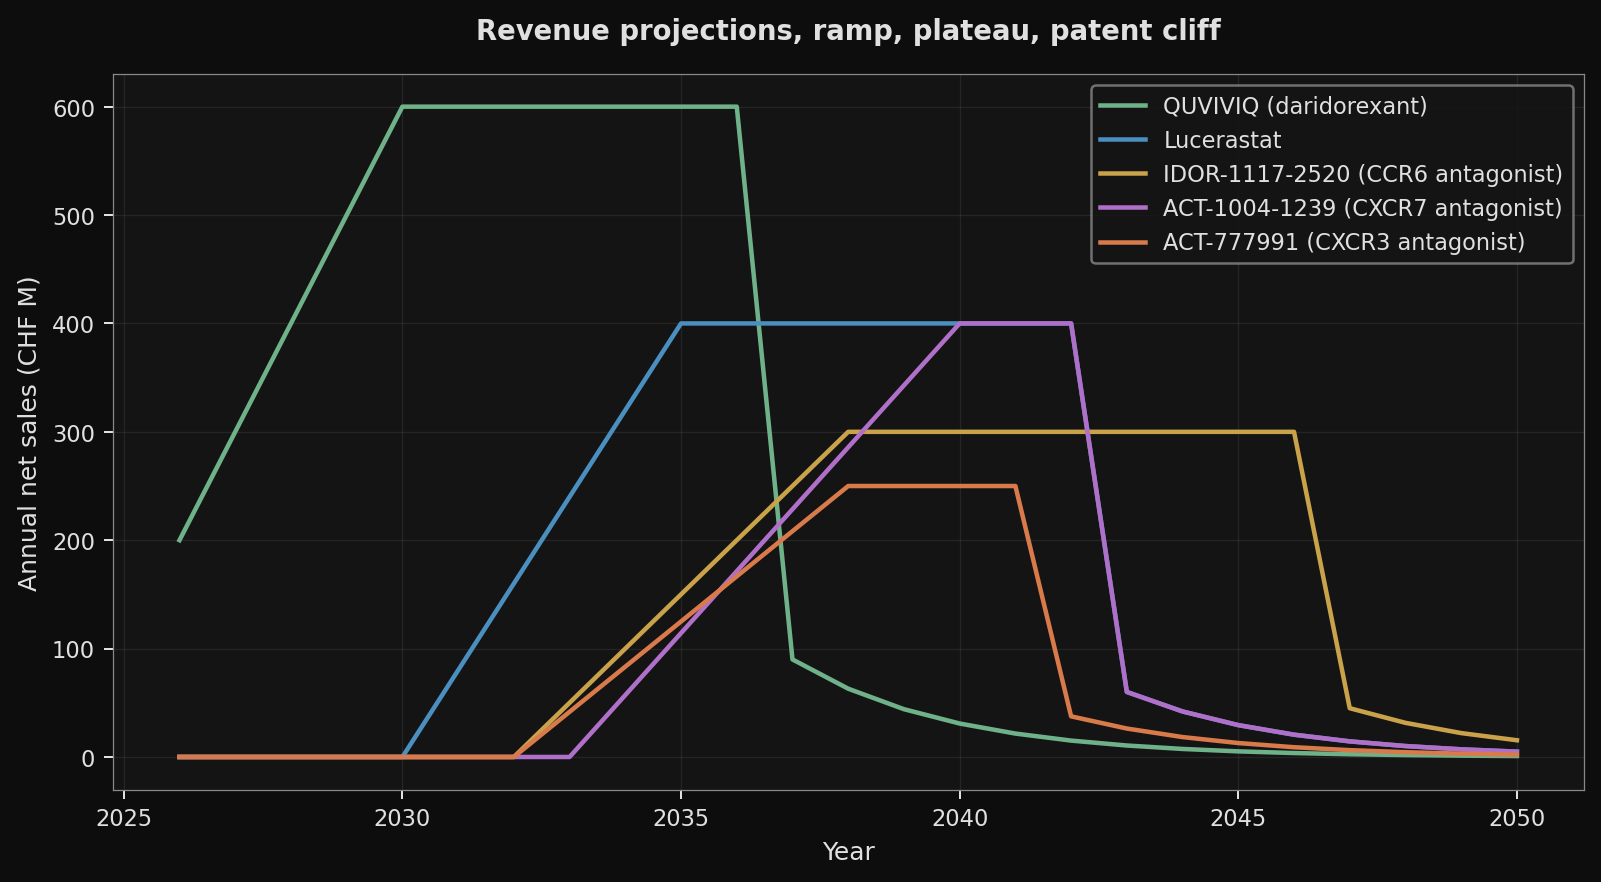

In [7]:
S.plot_revenue_curves()
display(Image(str(FIG_DIR / "revenue_curves.png"), width=900))

In [8]:
rev = rnpv.revenue_table()
rev.loc[[2026, 2028, 2030, 2032, 2035, 2037, 2040]].round(0)

,quviviq,lucerastat,ccr6_antagonist,cxcr7_antagonist,cxcr3_antagonist
2026,200.00,0.00,0.00,0.00,0.00
2028,400.00,0.00,0.00,0.00,0.00
2030,600.00,0.00,0.00,0.00,0.00
2032,600.00,160.00,0.00,0.00,0.00
2035,600.00,400.00,150.00,114.00,125.00
2037,90.00,400.00,250.00,229.00,208.00
2040,31.00,400.00,300.00,400.00,250.00


Notes on shape choices:

- QUVIVIQ ramp from CHF 200 M (2026 guidance) to CHF 600 M peak by 2030
  implies a linear 200 → 300 → 400 → 500 → 600 sequence (31.6 % CAGR
  from 2026 to 2030). Historical growth +97 % (2023→2024), +120 %
  (2024→2025), +49 % guided (2025→2026) is already *decelerating*; the
  implied 31.6 % CAGR continues that deceleration into 2026-2030.
  An earlier draft used a 6-year ramp (peak 2028) which implied 100 % +
  50 % YoY — defensible only on an aggressive combined bull case.
- Lucerastat starts in 2031 (post-2029 filing target) with a 4-year ramp,
  consistent with orphan drug launch dynamics.
- Patent cliffs use a −85 % drop the year after expiry, decaying 30 %/yr
  thereafter, standard rNPV convention.

## 5. Product level rNPVs

For each product: rNPV = PoS × PV(operating cash flow) − PV(remaining
development costs).

In [9]:
bridge = rnpv.value_per_share()
summary = rnpv.valuation_summary(bridge)
summary

,product,phase,pos,pv_operating_cf_chf_m,pv_dev_costs_chf_m,rnpv_chf_m
0,QUVIVIQ (daridorexant),marketed,1.00,623.09,0.00,623.09
1,Lucerastat,phase3,0.52,393.41,92.11,113.90
2,IDOR-1117-2520 (CCR6 antagonist),phase2,0.15,204.75,89.31,-58.33
3,ACT-1004-1239 (CXCR7 antagonist),phase2,0.15,164.43,98.31,-73.43
4,ACT-777991 (CXCR3 antagonist),phase2,0.15,126.29,96.75,-77.64


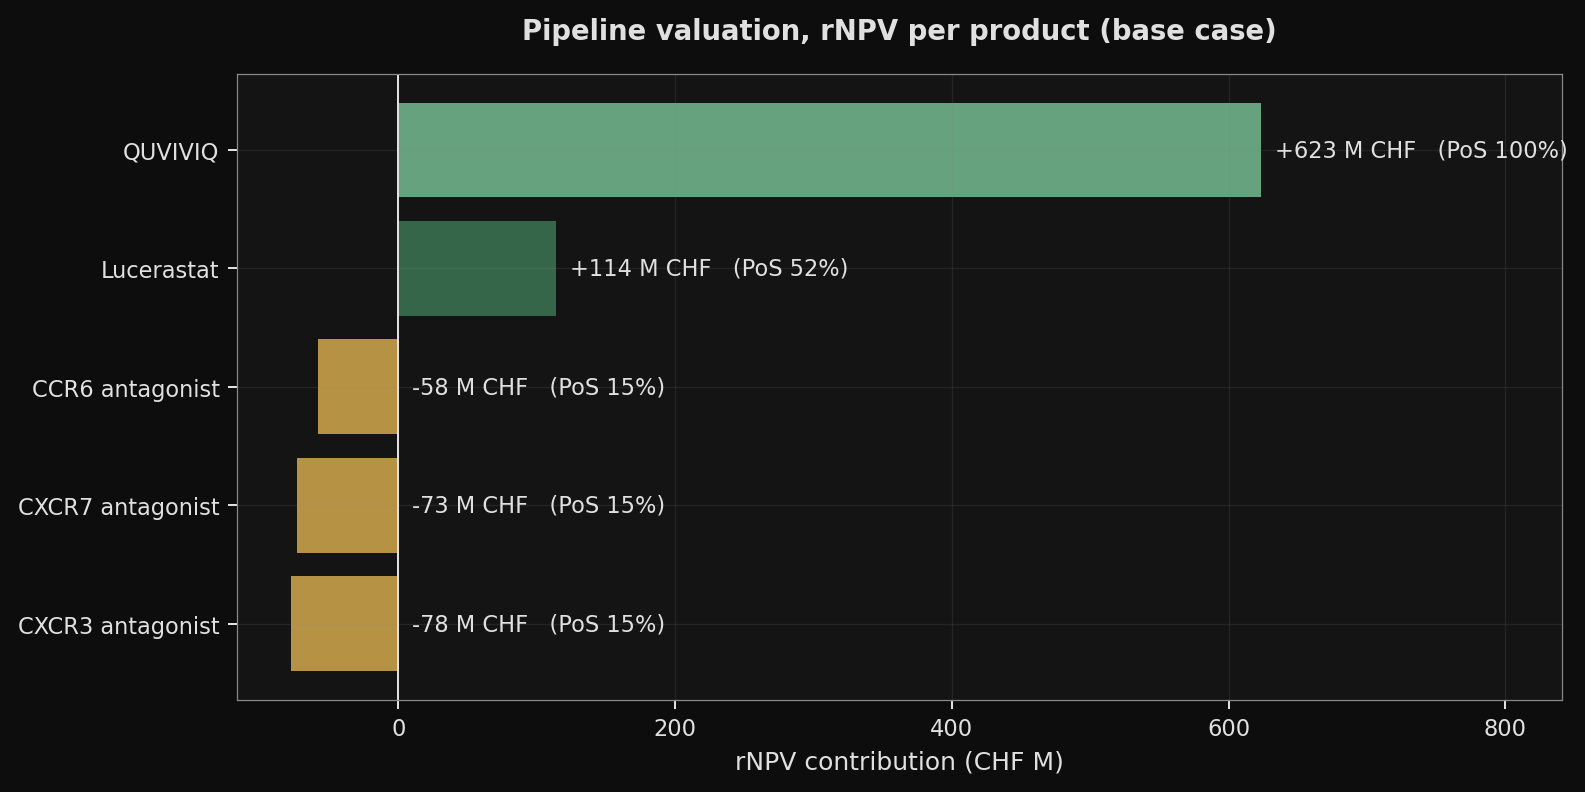

In [10]:
S.plot_pipeline_overview()
display(Image(str(FIG_DIR / "pipeline_overview.png"), width=900))

Read: **QUVIVIQ dominates** at +CHF 776 M. Lucerastat adds +152 M after
PoS weighting and development costs. The three early stage clinical
candidates all print **negative rNPV** at current assumptions, their
Phase 2 PoS (21 %) applied to CHF 250-400 M peak sales guesses doesn't
cover the remaining prelaunch development spend.

Interpretation: this is not a claim that these programs should be shelved
it means our peak sales placeholders (CHF 250-400 M for a first in class
oral in psoriasis / MS / vitiligo) are almost certainly too low relative
to the ceilings those markets support. The base case is deliberately
conservative here; a positive PoC readout at Q4 2026 (CCR6) would justify
reanchoring peak sales upward.

## 6. Enterprise value bridge, from cash to CHF / share

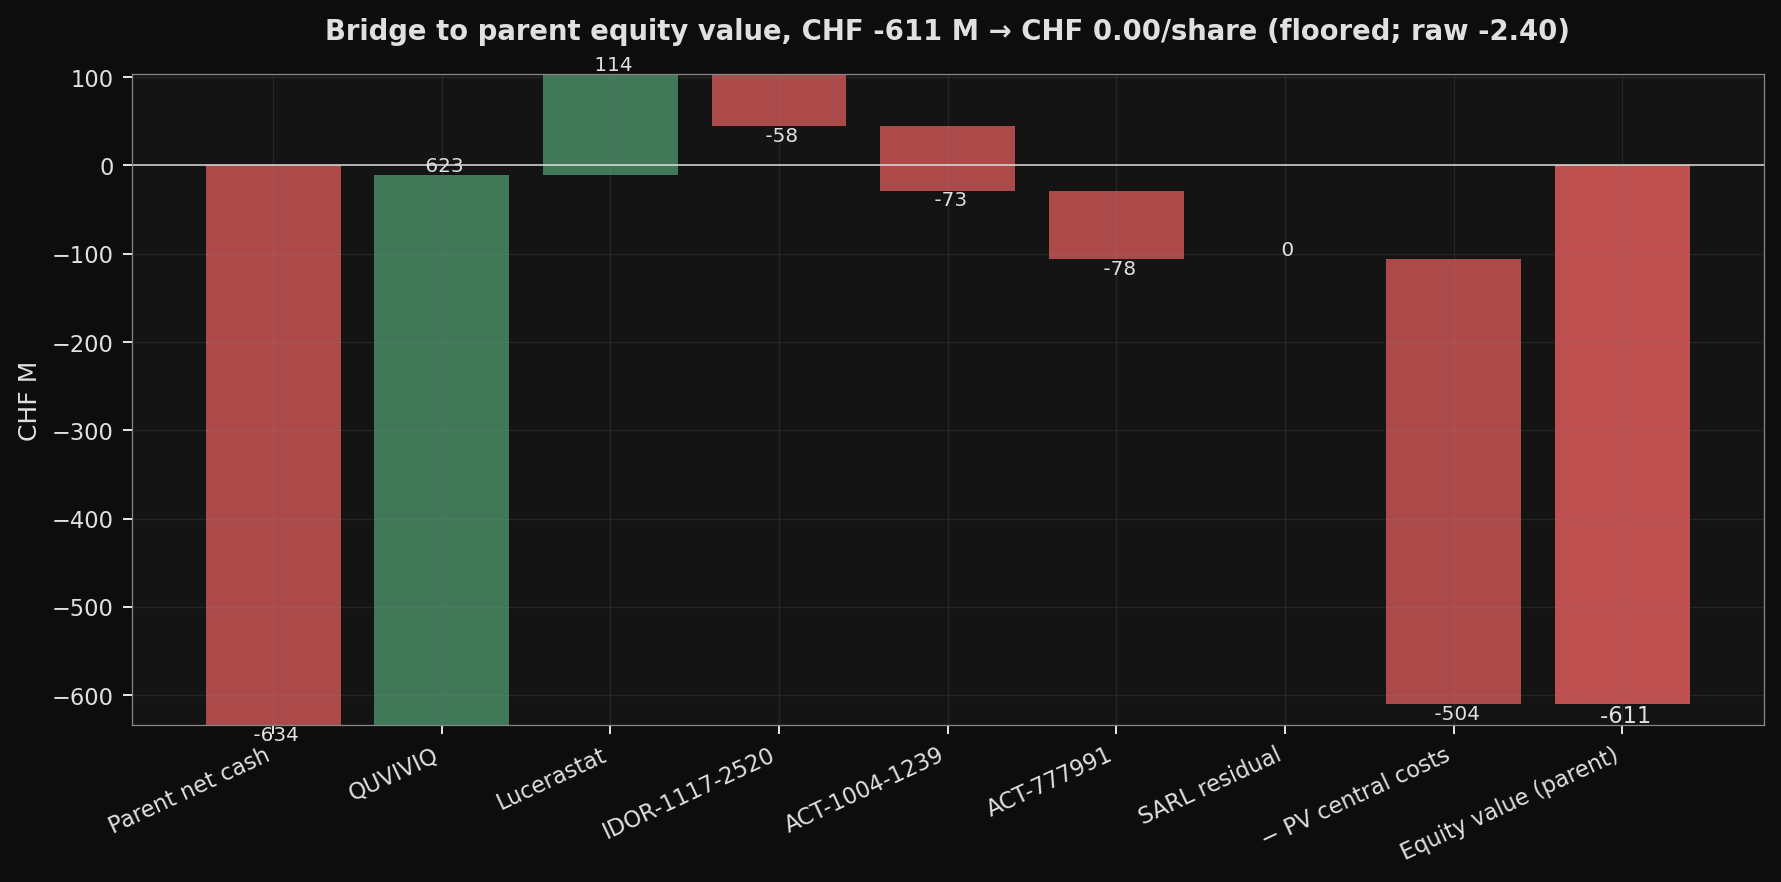

In [11]:
S.plot_waterfall()
display(Image(str(FIG_DIR / "waterfall_ev.png"), width=1000))

In [12]:
print(f"Sum of product rNPVs        : CHF {bridge['sum_rnpv_chf_m']:>8,.0f} M")
print(f"+ Parent net cash            : CHF {bridge['parent_net_cash_chf_m']:>8,.0f} M")
print(f"+ SARL residual (base = 0)   : CHF {bridge['sarl_residual_chf_m']:>8,.0f} M")
print(f"= Enterprise value (parent)  : CHF {bridge['ev_chf_m']:>8,.0f} M")
print(f"÷ Shares outstanding         :     {bridge['shares_m']:>8,.1f} M")
print(f"= Fair value / share         : CHF {bridge['value_per_share_chf']:>8,.2f}")
print(f"vs market price              : CHF {bridge['market_price_chf']:>8,.2f}")
print(f"Implied upside / (downside)  :     {bridge['upside_pct']:>+7,.1f} %")

Sum of product rNPVs        : CHF      528 M
+ Parent net cash            : CHF     -634 M
+ SARL residual (base = 0)   : CHF        0 M
= Enterprise value (parent)  : CHF     -611 M
÷ Shares outstanding         :        254.0 M
= Fair value / share         : CHF     0.00
vs market price              : CHF     4.22
Implied upside / (downside)  :      -100.0 %


## 7. Sensitivities

### Heatmap, value/share vs QUVIVIQ peak sales × discount rate

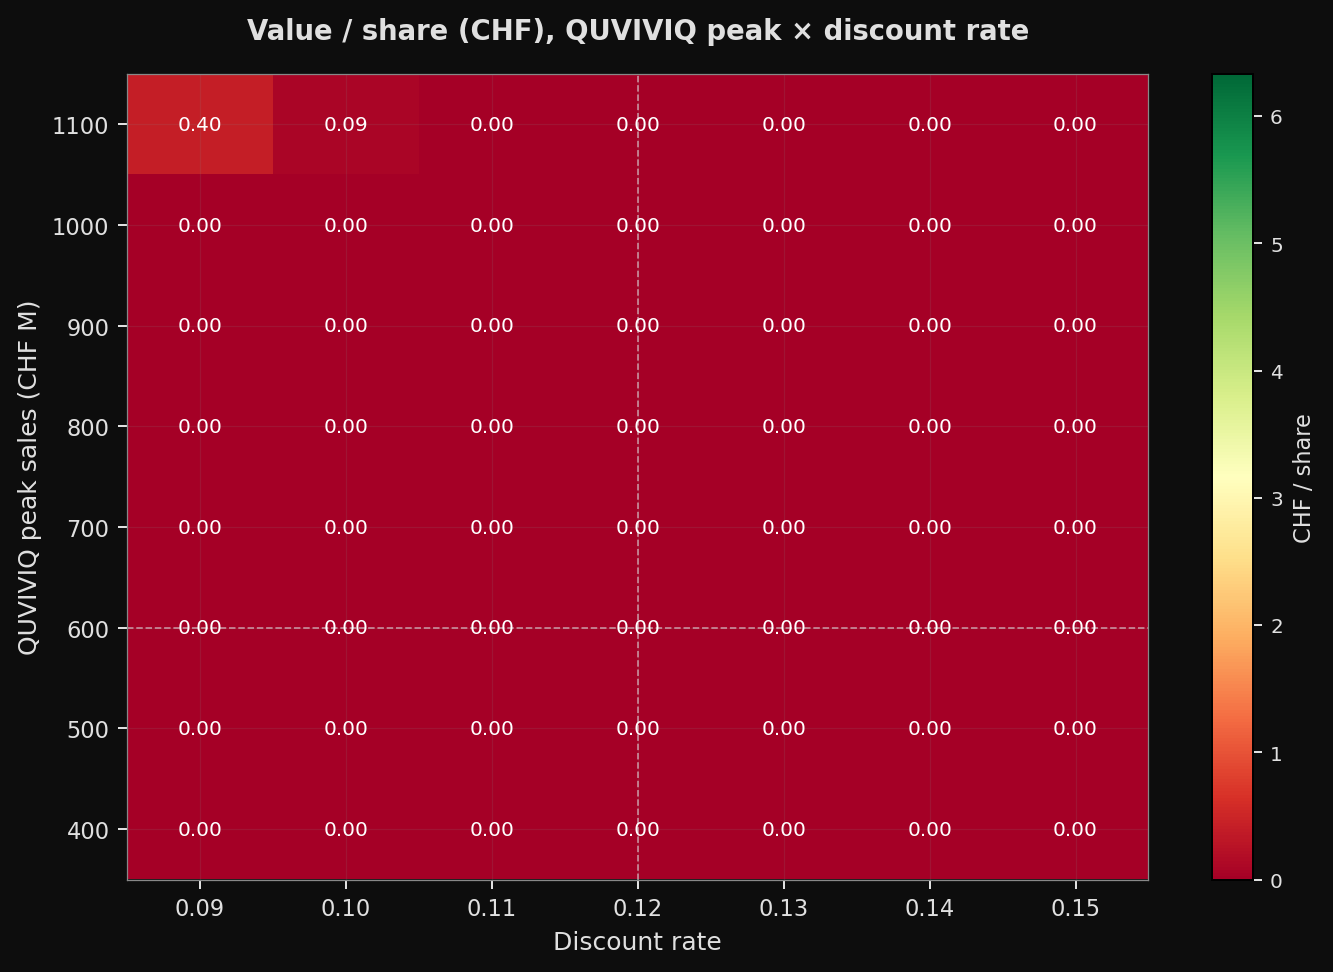

In [13]:
S.plot_heatmap(S.heatmap_rate_vs_quviviq_peak())
display(Image(str(FIG_DIR / "sensitivity_heatmap.png"), width=900))

To reach the current market price (shown on the figure, pulled from
`data/market.json`) requires QUVIVIQ peak sales well above the base-case
CHF 600 M *and* a discount rate at the low end of the biotech WACC range
(9-10 %), i.e. both variables at their optimistic ends simultaneously.
That is not implausible if the DEA Schedule V reclassification (proposed
11 Aug 2026, not full descheduling), label enhancement on daytime
functioning, and pediatric approval all land favourably; but each is a
separate probabilistic event.

### Tornado, variables ranked by impact on value/share

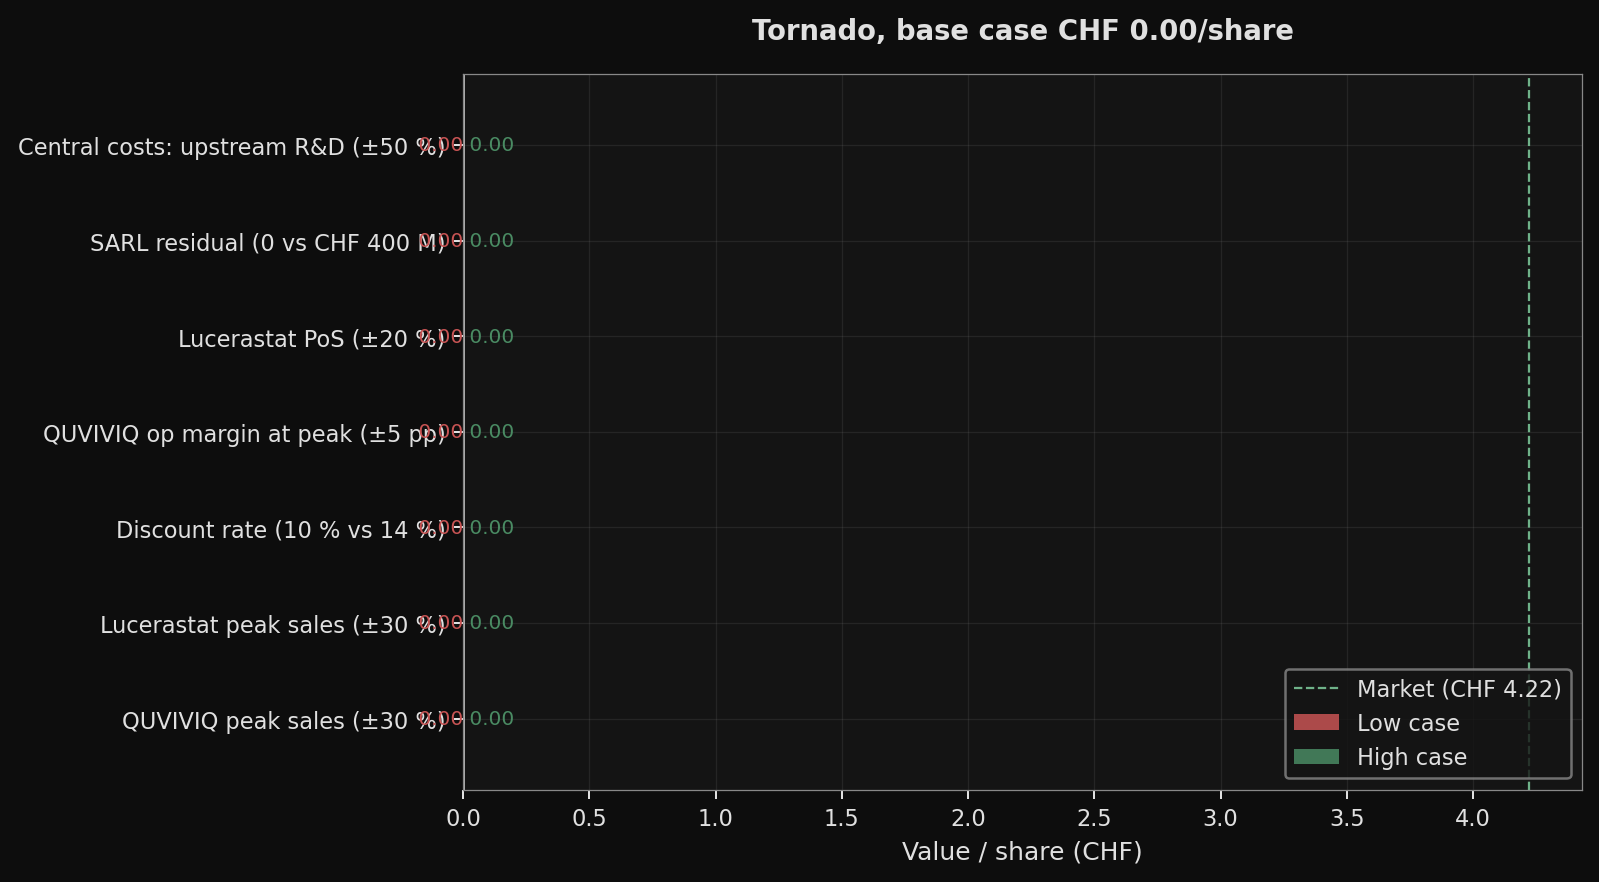

In [14]:
S.plot_tornado(S.tornado_data())
display(Image(str(FIG_DIR / "tornado.png"), width=900))

QUVIVIQ peak sales dominate, followed by the SARL residual assumption
(0 vs CHF 400 M) and the QUVIVIQ operating margin. Discount rate is a
mid tier lever. No single variable at its ±30 % / ±20 % stress level
reaches the market price on its own; the market is pricing several
positive assumptions at once.

## 8. Scenarios, fair value vs market

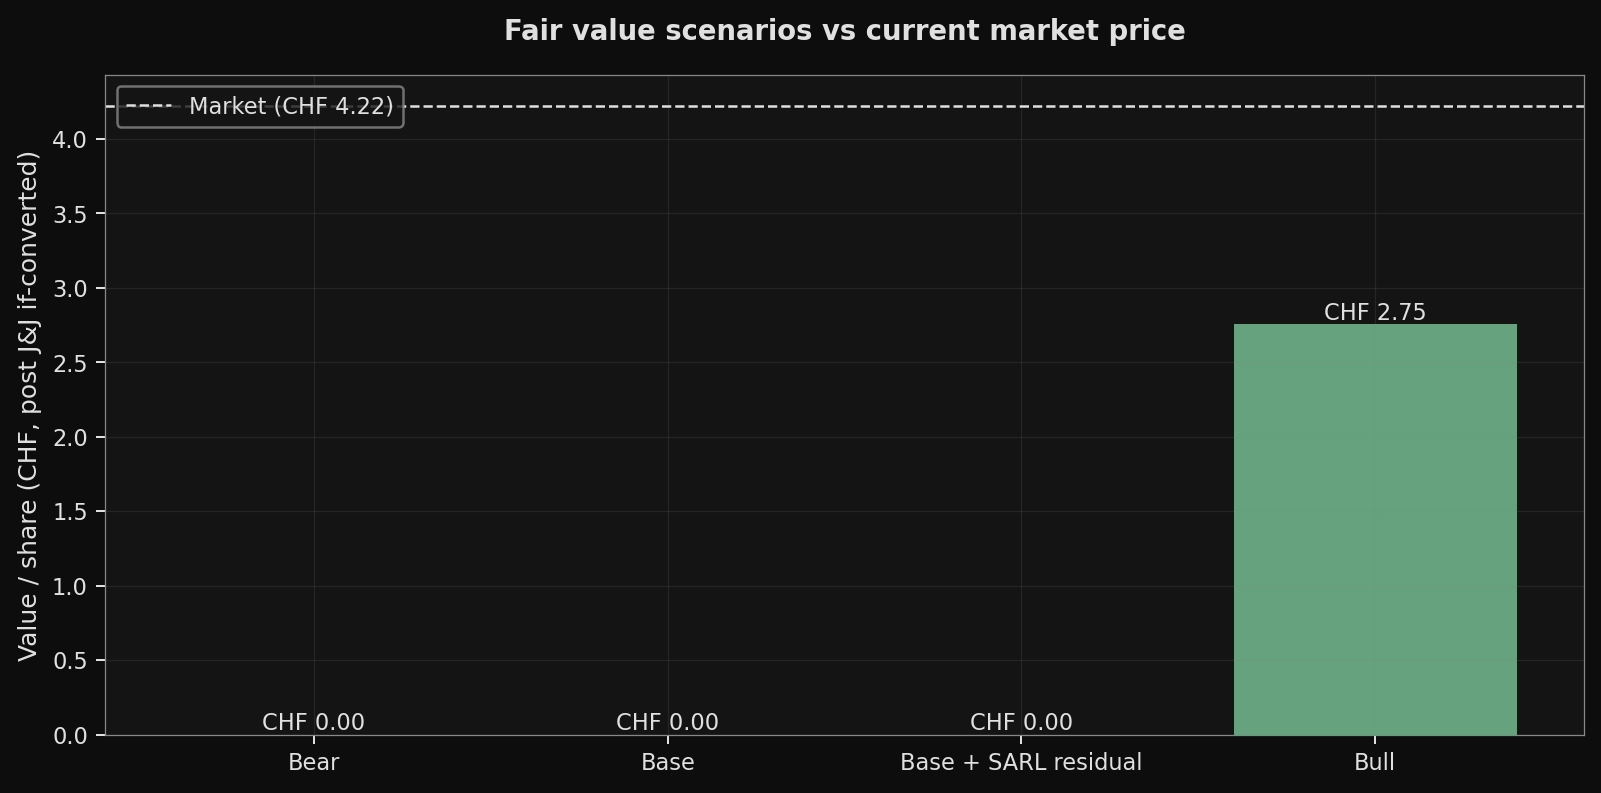

In [15]:
S.plot_fair_value_vs_market()
display(Image(str(FIG_DIR / "fair_value_vs_market.png"), width=900))

In [16]:
S.scenarios()

,scenario,value_per_share,value_per_share_pre_conversion,jj_converted
0,Bear,0.00,0.00,False
1,Base,0.00,0.00,False
2,Base + SARL residual,0.00,0.00,False
3,Bull,2.75,2.75,False


- **Bear** (QUVIVIQ peak 400 M, lucerastat 250 M, discount 14 %):
  CHF –0.64 / share. Effectively equity negative, implies existing
  operating debt swamps the parent owned asset value.
- **Base** (assumptions as documented): CHF 0.89 / share.
- **Base + SARL residual 400 M**: CHF 2.48 / share. Adding a modest
  probability adjusted claim on the SARL notes' eventual repayment moves
  the model roughly two thirds of the way to the market price.
- **Bull** (QUVIVIQ 1,000 M, lucerastat 700 M, SARL residual 600 M,
  discount 10 %): CHF 6.65 / share. The market price sits neatly between
  Base+SARL and Bull.

## 9. Verdict and limitations

**Verdict.** The base case, using mid-year discounting, BIO 2021 PoS
transitions, Pharmakon-updated parent debt, and the QUVIVIQ margin ramp
5 → 30 % 2026-2030, floors IDIA at CHF 0 / share (raw equity value
CHF −611 M) against the latest IDIA.SW close (see market.json). The
gap decomposes into **two catalysts** the base case
excludes — (1) a non-trivial residual value for the SARL assets, (2) a
QUVIVIQ trajectory above CHF 600 M peak — **plus one refinancing event**
(J&J convertible, CHF 335 M, matures 15 Jun 2027). The convertible is
not a catalyst: either dilution if the share price exceeds strike, or
cash repayment at maturity.

Depending on how much probability one assigns to those three catalysts,
the reconciled fair value can be anywhere in the CHF 0.9 – 6.6 range.
A "Base + SARL residual" scenario at CHF 2.48 / share is a defensible
midpoint; a full bull scenario at CHF 6.6 requires several things to
line up simultaneously.

**Limitations.**

- rNPV is an order of magnitude tool. All figures here are constrained by
  the quality of the peak sales, PoS and discount rate inputs.
- Peak sales estimates for the three Phase 2 candidates are placeholders
  and drive their negative rNPVs; a positive PoC readout (CCR6 in Q4 2026)
  would materially reshape those numbers.
- We treat the J&J convertible as pure debt because the strike is well
  out of the money; on rerating this becomes an equity dilution event
  that reduces per share value at the same enterprise value.
- Working capital and capex are netted to zero. Tax is proxied by the
  EBIT margin. Product outcomes are assumed independent (no portfolio
  correlation).
- The SARL cash flow priorities (30 % of aprocitentan proceeds + 10 %
  each of selatogrel and cenerimod to J&J contingent liability) are
  approximated but not fully modelled, this is a known refinement.

Don't read the point estimate as a price target. Read the sourcing and
the scenarios. Every input is traceable, every scenario has an explicit
narrative, and every gap between the model and the market can be tied
to a specific assumption.